In [1]:
import os
import zipfile
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms.v2 as transforms

from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
)

In [2]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames[:3]: 
        print(os.path.join(dirname, filename))

/kaggle/input/models/rijalulghodi/linearprobing-deit3-224-aptos/pytorch/default/1/best_deit3_aptos.pth
/kaggle/input/models/rijalulghodi/linearprobing-deit3-224-aptos/pytorch/default/1/.virtual_documents/__notebook_source__.ipynb
/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/augmented_raw/b2ffa3e18559_aug652.png
/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/augmented_raw/ec4649213ccf_aug727.png
/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/augmented_raw/b6a0e348a01e_aug499.png
/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/val_test/ec363f48867b.png
/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/val_test/17f6c7072f61.png
/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/val_test/a688f20f8895.png
/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/train_balanced/ef476be214d4.png
/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/train_balanced/b2ffa3e18559_aug652.png
/ka

In [3]:
SOURCE_NOTEBOOK_DIR = "/kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data"

BALANCED_DIR = os.path.join(SOURCE_NOTEBOOK_DIR, "train_balanced")
VAL_TEST_DIR = os.path.join(SOURCE_NOTEBOOK_DIR, "val_test")
AUGMENTED_DIR = os.path.join(SOURCE_NOTEBOOK_DIR, "augmented_raw")
METADATA_DIR = os.path.join(SOURCE_NOTEBOOK_DIR, "csv_metadata")

for name, path in [("BALANCED_DIR", BALANCED_DIR), ("VAL_TEST_DIR", VAL_TEST_DIR), ("AUGMENTED_DIR", AUGMENTED_DIR), 
                   ("METADATA_DIR", METADATA_DIR)]:
    if os.path.exists(path):
        n_files = len(os.listdir(path))
        print(f"{name}: {path} -> {n_files} file ditemukan")
    else:
        print(f"PERINGATAN: {name} tidak ditemukan di {path}")

BALANCED_DIR: /kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/train_balanced -> 6315 file ditemukan
VAL_TEST_DIR: /kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/val_test -> 1099 file ditemukan
AUGMENTED_DIR: /kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/augmented_raw -> 3752 file ditemukan
METADATA_DIR: /kaggle/input/datasets/rijalulghodi/aptos-processed/aptos_data/csv_metadata -> 3 file ditemukan


In [4]:
import os
import pandas as pd

# 2. Baca file CSV ke masing-masing variabel DataFrame
balanced_df = pd.read_csv(os.path.join(METADATA_DIR, 'balanced_train_data.csv'))
# balanced_df = balanced_df[~balanced_df['id_code'].str.contains('_aug', na=False)].reset_index(drop=True)
print("=== PENYARINGAN DATA ASLI (TIMPANG) ===")
print(f"Jumlah baris setelah filter: {len(balanced_df)}")

print("\nDistribusi kelas data asli yang timpang:")
print(balanced_df['diagnosis'].value_counts().sort_index())

val_df = pd.read_csv(os.path.join(METADATA_DIR, 'val_data.csv'))
test_df = pd.read_csv(os.path.join(METADATA_DIR, 'test_data.csv'))

# 3. Verifikasi jumlah data yang berhasil dimuat
print(f"Jumlah data balanced_df (Train): {len(balanced_df)}")
print(f"Jumlah data val_df (Validation) : {len(val_df)}")
print(f"Jumlah data test_df (Test)      : {len(test_df)}")

# Tampilkan 5 baris pertama dari balanced_df
balanced_df.head()

=== PENYARINGAN DATA ASLI (TIMPANG) ===
Jumlah baris setelah filter: 6315

Distribusi kelas data asli yang timpang:
diagnosis
0    1263
1    1263
2    1263
3    1263
4    1263
Name: count, dtype: int64
Jumlah data balanced_df (Train): 6315
Jumlah data val_df (Validation) : 549
Jumlah data test_df (Test)      : 550


,id_code,diagnosis,is_augmented
0,38f1901f214a,0,False
1,bd34a0639575,0,False
2,d25b8a8ad3c4,2,False
3,4d17559ac1e2,0,False
4,bda8c973b09d,2,False


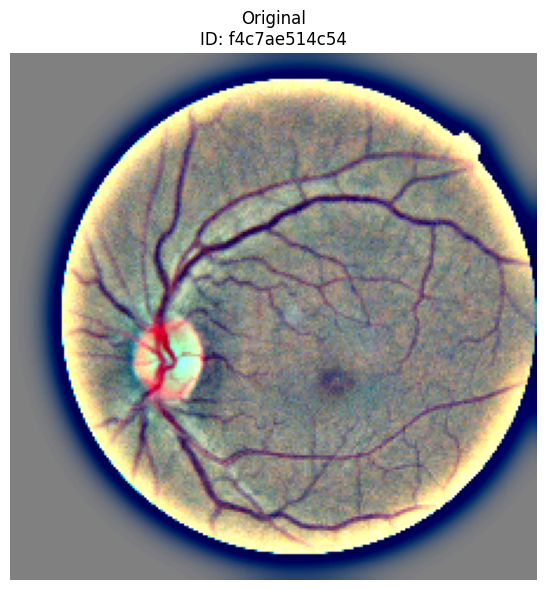

In [5]:
sample_row = val_df.iloc[0]
ben_graham_path = os.path.join(VAL_TEST_DIR, f"{sample_row['id_code']}.png")

ben_img = cv2.imread(ben_graham_path)
ben_img = cv2.cvtColor(ben_img, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 1, figsize=(12, 6))
axes.imshow(ben_img)
axes.set_title(f"Original\nID: {sample_row['id_code']}")
axes.axis('off')

plt.tight_layout()
plt.show()

In [6]:
train_transform = transforms.Compose([
    transforms.ToImage(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) 
])

In [7]:
val_test_transform = transforms.Compose([
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [8]:
class APTOSDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_name = f"{row['id_code']}.png"
        img_path = os.path.join(self.img_dir, img_name)

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(row['diagnosis'], dtype=torch.float32)
        return image, label

In [9]:
train_dataset = APTOSDataset(balanced_df, BALANCED_DIR, transform=train_transform)
val_dataset = APTOSDataset(val_df, VAL_TEST_DIR, transform=val_test_transform)
test_dataset = APTOSDataset(test_df, VAL_TEST_DIR, transform=val_test_transform)

In [10]:
class_counts = balanced_df['diagnosis'].value_counts().sort_index()
class_weights_sampler = 1.0 / class_counts
sample_weights = balanced_df['diagnosis'].map(class_weights_sampler).values
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

In [11]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, pin_memory=True, num_workers=2, persistent_workers=True)
# train_loader = DataLoader(train_dataset, batch_size=64, pin_memory=True, sampler=sampler, num_workers=2, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, pin_memory=True, num_workers=2, persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True, num_workers=2, persistent_workers=True)

images, labels = next(iter(train_loader))
print(f"Shape batch gambar (PyTorch format [B, C, H, W]): {images.shape}")
print(f"Shape batch label: {labels.shape}")

Shape batch gambar (PyTorch format [B, C, H, W]): torch.Size([64, 3, 224, 224])
Shape batch label: torch.Size([64])


# Inisiasi Model

In [12]:
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

NUM_CLASSES = 1

model = timm.create_model(
    "deit3_base_patch16_224.fb_in22k_ft_in1k",
    pretrained=True,
    num_classes=NUM_CLASSES,
    drop_path_rate=0.25
)
model = model.to(device)
print("Model DeiT III berhasil diinisialisasi!")

Menggunakan device: cuda


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Model DeiT III berhasil diinisialisasi!


In [13]:
for param in model.parameters():
    param.requires_grad = False

for param in model.head.parameters():
    param.requires_grad = True

In [14]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable_params:,} / Total: {total_params:,} ({trainable_params/total_params*100:.2f}%)")

Trainable: 769 / Total: 85,817,089 (0.00%)


In [15]:
criterion = nn.MSELoss()
scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None

In [16]:
def get_logits(outputs):
    """timm mengembalikan tensor logits langsung, berbeda dengan
    HF transformers yang mengembalikan objek dengan atribut .logits."""
    return outputs

def regression_to_class(outputs, num_classes=5):
    """Konversi output regresi kontinu menjadi label kelas diskrit (0..num_classes-1)."""
    return torch.round(torch.clamp(outputs, 0, num_classes - 1))

In [17]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, epoch, total_epochs):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    pbar = tqdm(dataloader, desc=f"Epoch {epoch+1}/{total_epochs} [Train]", leave=True)

    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        if scaler is not None:
            with torch.amp.autocast('cuda'):
                outputs = get_logits(model(images)).squeeze(-1)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = get_logits(model(images)).squeeze(-1)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)
        
        preds = regression_to_class(outputs)
        
        correct_predictions += torch.sum(preds == labels)
        total_samples += labels.size(0)

        current_loss = running_loss / total_samples
        current_acc = (correct_predictions.float() / total_samples).item()
        pbar.set_postfix({"mse_loss": f"{current_loss:.4f}", "acc": f"{current_acc:.4f}"})

    epoch_loss = running_loss / total_samples
    epoch_acc = (correct_predictions.float() / total_samples).item()
    
    return epoch_loss, epoch_acc

In [18]:
def validate_one_epoch(model, dataloader, criterion, device, epoch, total_epochs):
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    all_preds, all_labels = [], []

    pbar = tqdm(dataloader, desc=f"Epoch {epoch+1}/{total_epochs} [Val]  ", leave=True)

    with torch.no_grad():
        for images, labels in pbar:
            images = images.to(device)
            labels = labels.to(device)

            # Evaluasi dengan AMP Autocast agar cepat
            if torch.cuda.is_available():
                with torch.amp.autocast('cuda'):
                    outputs = get_logits(model(images)).squeeze(-1)
            else:
                outputs = get_logits(model(images)).squeeze(-1)

            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * images.size(0)
            
            preds = regression_to_class(outputs)
            
            correct_predictions += torch.sum(preds == labels)
            total_samples += labels.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            current_loss = running_loss / total_samples
            current_acc = (correct_predictions.float() / total_samples).item()
            pbar.set_postfix({"mse_loss": f"{current_loss:.4f}", "acc": f"{current_acc:.4f}"})

    epoch_loss = running_loss / total_samples
    epoch_acc = (correct_predictions.float() / total_samples).item()
    epoch_qwk = cohen_kappa_score(all_labels, all_preds, weights="quadratic")
    
    return epoch_loss, epoch_acc, epoch_qwk

In [19]:
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [], 'val_qwk': []
}

In [20]:
best_val_qwk = -1.0
best_val_loss = float('inf')
patience = 10 
patience_counter = 0
BEST_MODEL_PATH = "best_deit3_aptos.pth"

In [21]:
import torch.optim as optim
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR

EPOCHS_STAGE1 = 8
WARMUP_EPOCHS = 2

optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)

warmup_scheduler = LinearLR(
    optimizer,
    start_factor=0.1,
    end_factor=1.0,
    total_iters=WARMUP_EPOCHS
)

cosine_scheduler = CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS_STAGE1 - WARMUP_EPOCHS
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[WARMUP_EPOCHS]
)

In [22]:
print("=== TAHAP 1: Linear Probing ===")
for epoch in range(EPOCHS_STAGE1):
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1} — Learning Rate: {current_lr:.2e}")

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device, epoch, EPOCHS_STAGE1)
    val_loss, val_acc, val_qwk = validate_one_epoch(model, val_loader, criterion, device, epoch, EPOCHS_STAGE1)

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_qwk'].append(val_qwk)

    print(f"Val QWK: {val_qwk:.4f} | Val Acc: {val_acc:.4f} | Val MSE Loss: {val_loss:.4f}")

    if val_qwk > best_val_qwk: # Disimpan berdasarkan QWK Terbaik
        best_val_qwk = val_qwk
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"--> Model terbaik disimpan! (Val QWK: {val_qwk:.4f})\n")
    # else:
    #     patience_counter += 1
    #     print(f"({patience_counter}/{patience})\n")
    #     if patience_counter >= patience:
    #         print(f"Early stopping Tahap 1 pada epoch {epoch+1}.")
    #         break

=== TAHAP 1: Linear Probing ===
Epoch 1 — Learning Rate: 1.00e-04


Epoch 1/8 [Train]:   0%|          | 0/99 [00:00<?, ?it/s]

Epoch 1/8 [Val]  :   0%|          | 0/18 [00:00<?, ?it/s]

Val QWK: 0.4024 | Val Acc: 0.3752 | Val MSE Loss: 1.3392
--> Model terbaik disimpan! (Val QWK: 0.4024)

Epoch 2 — Learning Rate: 5.50e-04


Epoch 2/8 [Train]:   0%|          | 0/99 [00:00<?, ?it/s]

...

Epoch 7/8 [Val]  :   0%|          | 0/18 [00:00<?, ?it/s]

Val QWK: 0.7171 | Val Acc: 0.5811 | Val MSE Loss: 0.6594
Epoch 8 — Learning Rate: 6.70e-05


Epoch 8/8 [Train]:   0%|          | 0/99 [00:00<?, ?it/s]

Epoch 8/8 [Val]  :   0%|          | 0/18 [00:00<?, ?it/s]

Val QWK: 0.7248 | Val Acc: 0.5701 | Val MSE Loss: 0.6453
--> Model terbaik disimpan! (Val QWK: 0.7248)



In [23]:
# ===== TAHAP 2: Muat model terbaik dari Tahap 1, lalu buka 4 blok terakhir =====
# model.load_state_dict(torch.load('/kaggle/input/models/rijalulghodi/linearprobing-deit3-224-aptos/pytorch/default/1/best_deit3_aptos.pth'))
model.load_state_dict(torch.load(BEST_MODEL_PATH))

for param in model.parameters():
    param.requires_grad = False

for i in range(1, 12):  # buka blok Transformers
    for param in model.blocks[i].parameters():
        param.requires_grad = True

for param in model.norm.parameters():
    param.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"[Tahap 2] Trainable: {trainable_params:,} / Total: {total_params:,} ({trainable_params/total_params*100:.2f}%)")

EPOCHS_STAGE2 = 40
WARMUP_EPOCHS_STAGE2 = 5

optimizer = optim.AdamW(model.parameters(), lr=7e-4, weight_decay=0.2)

warmup_scheduler2 = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS_STAGE2)
cosine_scheduler2 = CosineAnnealingLR(optimizer, T_max=EPOCHS_STAGE2 - WARMUP_EPOCHS_STAGE2)
scheduler = SequentialLR(optimizer, schedulers=[warmup_scheduler2, cosine_scheduler2], milestones=[WARMUP_EPOCHS_STAGE2])

[Tahap 2] Trainable: 77,985,024 / Total: 85,817,089 (90.87%)


In [24]:
patience_counter = 0  # reset patience untuk tahap baru

print("=== TAHAP 2: Fine-tuning ===")

for epoch in range(EPOCHS_STAGE2):
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1} — Learning Rate: {current_lr:.2e}")

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device, epoch, EPOCHS_STAGE2)
    val_loss, val_acc, val_qwk = validate_one_epoch(model, val_loader, criterion, device, epoch, EPOCHS_STAGE2)

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_qwk'].append(val_qwk)

    print(f"Val QWK: {val_qwk:.4f} | Val Acc: {val_acc:.4f} | Val MSE Loss: {val_loss:.4f}")

    if val_qwk > best_val_qwk:
        best_val_qwk = val_qwk
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"--> Model terbaik disimpan! (Val QWK: {val_qwk:.4f})\n")
    # else:
    #     patience_counter += 1
    #     print(f"({patience_counter}/{patience})\n")
    #     if patience_counter >= patience:
    #         print(f"Early stopping epoch {epoch+1}.")
    #         break
            
print(f"\nTahap 2 selesai. Best Val Loss keseluruhan: {best_val_loss:.4f}")
print(f"\nBest QWK keseluruhan: {best_val_qwk:.4f}")

=== TAHAP 2: Fine-tuning 4 blok terakhir + norm ===
Epoch 1 — Learning Rate: 7.00e-05


Epoch 1/40 [Train]:   0%|          | 0/99 [00:00<?, ?it/s]

Epoch 1/40 [Val]  :   0%|          | 0/18 [00:00<?, ?it/s]

Val QWK: 0.8711 | Val Acc: 0.7359 | Val MSE Loss: 0.3565
--> Model terbaik disimpan! (Val QWK: 0.8711)

Epoch 2 — Learning Rate: 1.96e-04


Epoch 2/40 [Train]:   0%|          | 0/99 [00:00<?, ?it/s]

...

Epoch 39/40 [Val]  :   0%|          | 0/18 [00:00<?, ?it/s]

Val QWK: 0.8842 | Val Acc: 0.8179 | Val MSE Loss: 0.3425
Epoch 40 — Learning Rate: 1.41e-06


Epoch 40/40 [Train]:   0%|          | 0/99 [00:00<?, ?it/s]

Epoch 40/40 [Val]  :   0%|          | 0/18 [00:00<?, ?it/s]

Val QWK: 0.8839 | Val Acc: 0.8179 | Val MSE Loss: 0.3424

Tahap 2 selesai. Best Val Loss keseluruhan: 0.3801

Best QWK keseluruhan: 0.8849


# Evaluasi

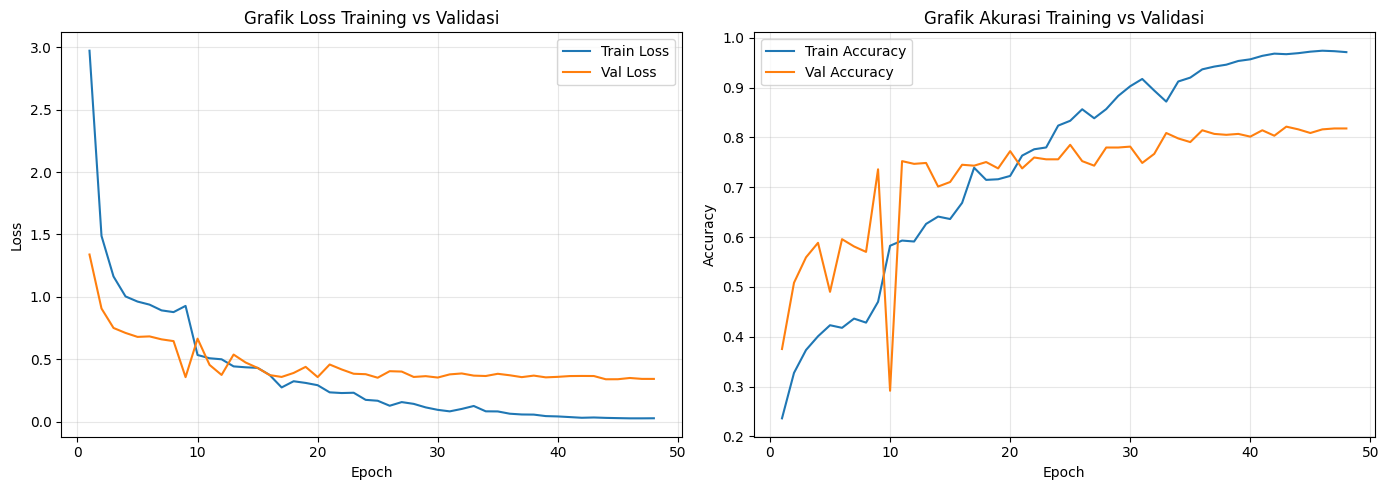

In [25]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history['train_loss'], label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'], label='Val Loss')
axes[0].set_title('Grafik Loss Training vs Validasi')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history['train_acc'], label='Train Accuracy')
axes[1].plot(epochs_range, history['val_acc'], label='Val Accuracy')
axes[1].set_title('Grafik Akurasi Training vs Validasi')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves_deit3.png", dpi=150)
plt.show()

In [26]:
model.eval()

all_test_preds, all_test_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = get_logits(model(images)).squeeze(-1)
        preds = torch.round(torch.clamp(outputs, 0, 4))

        all_test_preds.extend(preds.cpu().numpy())
        all_test_labels.extend(labels.cpu().numpy())

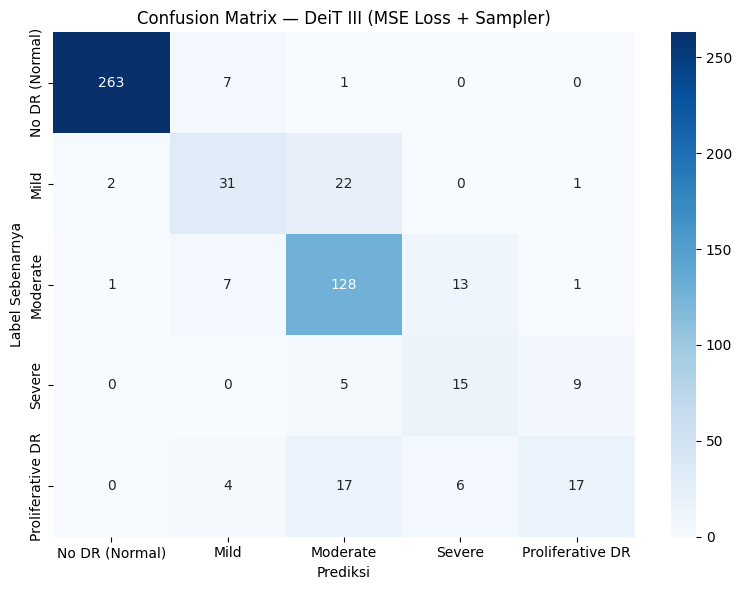

Classification Report (Data Testing):
                  precision    recall  f1-score   support

  No DR (Normal)     0.9887    0.9705    0.9795       271
            Mild     0.6327    0.5536    0.5905        56
        Moderate     0.7399    0.8533    0.7926       150
          Severe     0.4412    0.5172    0.4762        29
Proliferative DR     0.6071    0.3864    0.4722        44

        accuracy                         0.8255       550
       macro avg     0.6819    0.6562    0.6622       550
    weighted avg     0.8252    0.8255    0.8218       550

Akurasi pada Data Testing : 82.55%
QWK pada Data Testing     : 0.8877


In [27]:
label_names = {
    0: "No DR (Normal)",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}
CLASS_NAMES = [label_names[i] for i in range(5)]

# --- Confusion Matrix ---
cm = confusion_matrix(all_test_labels, all_test_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix — DeiT III (MSE Loss + Sampler)')
plt.xlabel('Prediksi')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.savefig("confusion_matrix_deit3_mse.png", dpi=150)
plt.show()

report = classification_report(all_test_labels, all_test_preds, target_names=CLASS_NAMES, digits=4)
print("Classification Report (Data Testing):")
print(report)

# --- Metrik ringkasan ---
test_acc = accuracy_score(all_test_labels, all_test_preds)
test_qwk = cohen_kappa_score(all_test_labels, all_test_preds, weights="quadratic")

print(f"Akurasi pada Data Testing : {test_acc*100:.2f}%")
print(f"QWK pada Data Testing     : {test_qwk:.4f}")

Mengumpulkan prediksi dari seluruh data training...


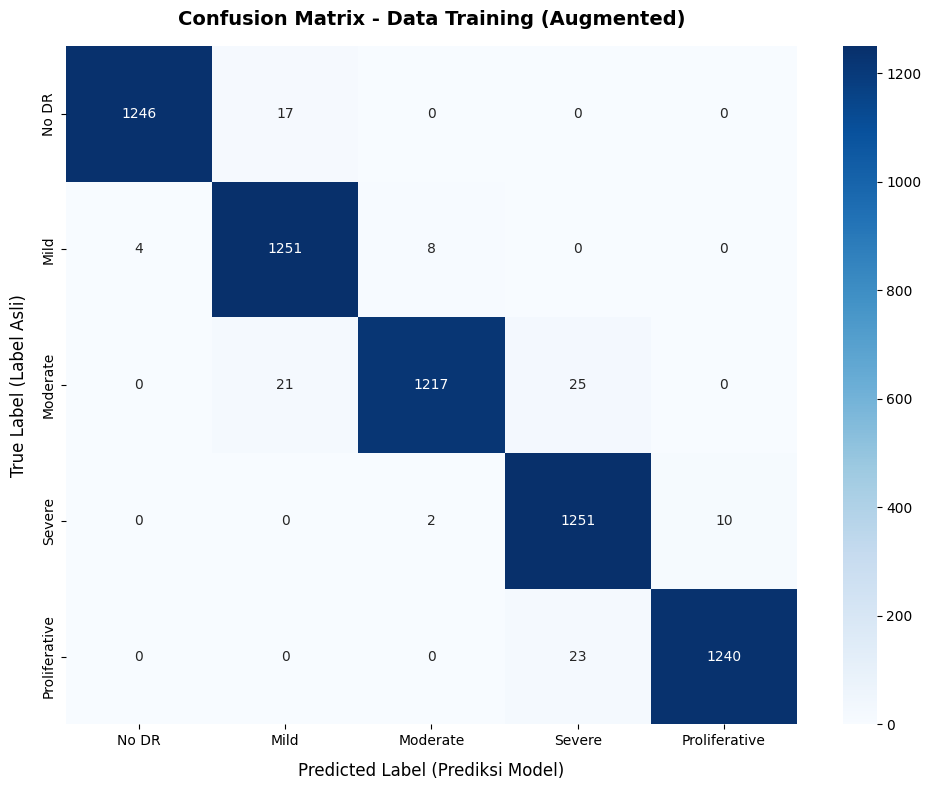

In [31]:
# =====================================================================
# PROSES EKSTRAKSI PREDIKSI (PASTIKAN VARIABLE MODEL & LOADER SUDAH ADA)
# =====================================================================
model.eval()  # Set model ke mode evaluasi

all_train_preds = []
all_train_labels = []

with torch.no_grad():
    for images, labels in train_loader:
        images = images.to(device)

        # Menggunakan AMP Autocast jika GPU tersedia agar proses cepat
        if torch.cuda.is_available():
            with torch.amp.autocast("cuda"):
                outputs = get_logits(model(images)).squeeze(-1)
                preds = torch.round(torch.clamp(outputs, 0, 4))
        else:
            outputs = model(images)

        # Simpan hasil ke dalam list
        all_train_preds.extend(preds.cpu().numpy().flatten())
        all_train_labels.extend(labels.numpy())

# =====================================================================
# GENERATE DAN PLOT CONFUSION MATRIX
# =====================================================================
cm_train = confusion_matrix(all_train_labels, all_train_preds)
class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix Data Training')
plt.xlabel('Prediksi')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()
